In [14]:
from pathlib import Path
from datetime import datetime, timezone
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
HORIZON_HOURS = 6
DATASET_NAME = "PRSA_Data_Wanliu_20130301-20170228.csv"

PROJECT_ROOT = None
DATA_PATH = None

for possible_root in [Path.cwd(), *Path.cwd().parents]:
    candidate = possible_root / "data" / "raw" / DATASET_NAME
    if candidate.exists():
        PROJECT_ROOT = possible_root
        DATA_PATH = candidate
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        f"No se encontró {DATASET_NAME}. "
        "Colócalo en data/raw/ dentro del proyecto."
    )

print("Raíz del proyecto:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)


Raíz del proyecto: c:\Users\PC\Proyectos\beijing-pm25-crisp-mlq
Dataset: c:\Users\PC\Proyectos\beijing-pm25-crisp-mlq\data\raw\PRSA_Data_Wanliu_20130301-20170228.csv


In [15]:
raw = pd.read_csv(DATA_PATH)

print("Dimensiones originales:", raw.shape)
print("\nColumnas:")
print(raw.columns.tolist())
print("\nTipos de datos:")
display(raw.dtypes.to_frame("tipo"))
print("\nValores nulos por columna:")
display(raw.isna().sum().to_frame("nulos"))
print("\nFilas duplicadas completas:", raw.duplicated().sum())
display(raw.head())


Dimensiones originales: (35064, 18)

Columnas:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

Tipos de datos:


,tipo
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64



Valores nulos por columna:


,nulos
No,0
year,0
month,0
day,0
hour,0
PM2.5,382
PM10,284
SO2,575
NO2,1070
CO,1812



Filas duplicadas completas: 0


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,8.0,8.0,6.0,28.0,400.0,52.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Wanliu
1,2,2013,3,1,1,9.0,9.0,6.0,28.0,400.0,50.0,-1.1,1023.2,-18.2,0.0,N,4.7,Wanliu
2,3,2013,3,1,2,3.0,6.0,NaN,19.0,400.0,55.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Wanliu
3,4,2013,3,1,3,11.0,30.0,8.0,14.0,NaN,NaN,-1.4,1024.5,-19.4,0.0,NW,3.1,Wanliu
4,5,2013,3,1,4,3.0,13.0,9.0,NaN,300.0,54.0,-2.0,1025.2,-19.5,0.0,N,2.0,Wanliu


In [16]:
required_date_columns = {"year", "month", "day", "hour"}
missing_date_columns = required_date_columns - set(raw.columns)
if missing_date_columns:
    raise ValueError(f"Faltan columnas de fecha: {missing_date_columns}")

df = raw.copy()

df["timestamp"] = pd.to_datetime(
    {
        "year": df["year"],
        "month": df["month"],
        "day": df["day"],
        "hour": df["hour"],
    },
    errors="coerce",
)

invalid_dates = int(df["timestamp"].isna().sum())
df = df.dropna(subset=["timestamp"]).copy()
df = df.sort_values("timestamp")
duplicate_timestamps = int(df["timestamp"].duplicated().sum())
df = df.drop_duplicates(subset=["timestamp"], keep="first")

rename_map = {
    "PM2.5": "pm25",
    "PM10": "pm10",
    "SO2": "so2",
    "NO2": "no2",
    "CO": "co",
    "O3": "o3",
    "TEMP": "temp",
    "PRES": "pres",
    "DEWP": "dewp",
    "RAIN": "rain",
    "WSPM": "wspm",
}
df = df.rename(columns=rename_map)

df = df.set_index("timestamp")
rows_before_asfreq = len(df)
df = df.asfreq("h")
inserted_hour_rows = len(df) - rows_before_asfreq

numeric_source_columns = [
    "pm25", "pm10", "so2", "no2", "co", "o3",
    "temp", "pres", "dewp", "rain", "wspm",
]
for col in numeric_source_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "wd" not in df.columns:
    raise ValueError("No se encontró la columna categórica 'wd'.")
df["wd"] = df["wd"].astype("object")

print("Periodo:", df.index.min(), "a", df.index.max())
print("Filas después de ordenar y normalizar frecuencia:", len(df))
print("Fechas inválidas descartadas:", invalid_dates)
print("Timestamps duplicados retirados:", duplicate_timestamps)
print("Filas horarias añadidas para completar huecos:", inserted_hour_rows)
print("\nNulos después de normalizar:")
display(df[numeric_source_columns + ["wd"]].isna().sum().to_frame("nulos"))


Periodo: 2013-03-01 00:00:00 a 2017-02-28 23:00:00
Filas después de ordenar y normalizar frecuencia: 35064
Fechas inválidas descartadas: 0
Timestamps duplicados retirados: 0
Filas horarias añadidas para completar huecos: 0

Nulos después de normalizar:


,nulos
pm25,382
pm10,284
so2,575
no2,1070
co,1812
o3,2107
temp,20
pres,20
dewp,20
rain,20


,cantidad
Registros originales,35064
Registros en serie horaria,35064
Filas añadidas para completar horas ausentes,0
PM2.5 nulo,382
PM10 nulo,284
Dirección del viento (wd) nula,123


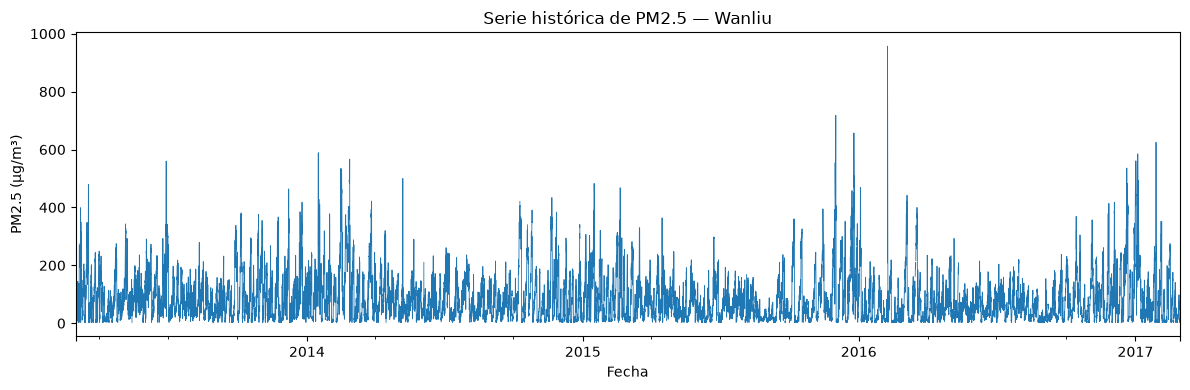

In [17]:
expected_hours = pd.date_range(df.index.min(), df.index.max(), freq="h")

quality_summary = pd.Series({
    "Registros originales": len(raw),
    "Registros en serie horaria": len(df),
    "Filas añadidas para completar horas ausentes": inserted_hour_rows,
    "PM2.5 nulo": int(df["pm25"].isna().sum()),
    "PM10 nulo": int(df["pm10"].isna().sum()),
    "Dirección del viento (wd) nula": int(df["wd"].isna().sum()),
})
display(quality_summary.to_frame("cantidad"))

plt.figure(figsize=(12, 4))
df["pm25"].plot(linewidth=0.6)
plt.title("Serie histórica de PM2.5 — Wanliu")
plt.xlabel("Fecha")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()


In [18]:
H = HORIZON_HOURS

numeric_measurements = [
    "pm10", "so2", "no2", "co", "o3",
    "temp", "pres", "dewp", "rain", "wspm",
]
missing_measurements = set(numeric_measurements + ["pm25", "wd"]) - set(df.columns)
if missing_measurements:
    raise ValueError(f"Faltan columnas necesarias: {missing_measurements}")

X_all = pd.DataFrame(index=df.index)

# Mediciones contemporáneas disponibles en la hora de origen.
for col in numeric_measurements:
    X_all[col] = df[col]

X_all["wd"] = df["wd"]
X_all["pm25_t"] = df["pm25"]

# Historial de PM2.5 conocido hasta t.
for lag in [1, 2, 3, 6, 12, 24]:
    X_all[f"pm25_lag_{lag}"] = df["pm25"].shift(lag)

# Las ventanas incluyen el valor actual t, pero nunca t+1 ni horas posteriores.
for window in [6, 12, 24]:
    rolling = df["pm25"].rolling(window=window, min_periods=max(2, window // 2))
    X_all[f"pm25_mean_{window}"] = rolling.mean()
    X_all[f"pm25_std_{window}"] = rolling.std()

# Calendario cíclico.
hour = df.index.hour
day_of_week = df.index.dayofweek
month = df.index.month
day_of_year = df.index.dayofyear

X_all["hour_sin"] = np.sin(2 * np.pi * hour / 24)
X_all["hour_cos"] = np.cos(2 * np.pi * hour / 24)
X_all["weekday_sin"] = np.sin(2 * np.pi * day_of_week / 7)
X_all["weekday_cos"] = np.cos(2 * np.pi * day_of_week / 7)
X_all["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
X_all["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)
X_all["yearday_sin"] = np.sin(2 * np.pi * (day_of_year - 1) / 365.25)
X_all["yearday_cos"] = np.cos(2 * np.pi * (day_of_year - 1) / 365.25)

# Objetivo y timestamp objetivo: exactamente seis horas después.
y_all = df["pm25"].shift(-H)
target_timestamp = pd.Series(df.index, index=df.index).shift(-H)

supervised = X_all.copy()
supervised["target_pm25_t_plus_6"] = y_all
supervised["target_timestamp"] = target_timestamp

# El PM2.5 actual debe existir para que la predicción y la referencia
# de persistencia representen un caso operativo real.
usable_mask = (
    supervised["target_pm25_t_plus_6"].notna()
    & supervised["pm25_t"].notna()
    & supervised["target_timestamp"].notna()
)
supervised = supervised.loc[usable_mask].copy()

FEATURE_COLUMNS = X_all.columns.tolist()
NUMERIC_FEATURES = [c for c in FEATURE_COLUMNS if c != "wd"]
CATEGORICAL_FEATURES = ["wd"]

X = supervised[FEATURE_COLUMNS]
y = supervised["target_pm25_t_plus_6"].astype(float)

print("Variables predictoras:", len(FEATURE_COLUMNS))
print("Ejemplos supervisados utilizables:", len(supervised))
print("Objetivo:", f"PM2.5 exactamente {H} horas después")
print("Primer origen:", supervised.index.min())
print("Último origen:", supervised.index.max())
print("\nVariables:")
print(FEATURE_COLUMNS)


Variables predictoras: 32
Ejemplos supervisados utilizables: 34374
Objetivo: PM2.5 exactamente 6 horas después
Primer origen: 2013-03-01 00:00:00
Último origen: 2017-02-28 17:00:00

Variables:
['pm10', 'so2', 'no2', 'co', 'o3', 'temp', 'pres', 'dewp', 'rain', 'wspm', 'wd', 'pm25_t', 'pm25_lag_1', 'pm25_lag_2', 'pm25_lag_3', 'pm25_lag_6', 'pm25_lag_12', 'pm25_lag_24', 'pm25_mean_6', 'pm25_std_6', 'pm25_mean_12', 'pm25_std_12', 'pm25_mean_24', 'pm25_std_24', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos', 'yearday_sin', 'yearday_cos']


C:\Users\PC\AppData\Local\Temp\ipykernel_15400\2178448526.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  day_of_week = df.index.dayofweek
C:\Users\PC\AppData\Local\Temp\ipykernel_15400\2178448526.py:34: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  day_of_year = df.index.dayofyear


In [19]:
n = len(supervised)
cut_train = supervised.index[int(n * 0.70)]
cut_validation = supervised.index[int(n * 0.85)]

train = supervised.loc[supervised["target_timestamp"] < cut_train].copy()
validation = supervised.loc[
    (supervised.index >= cut_train)
    & (supervised["target_timestamp"] < cut_validation)
].copy()
test = supervised.loc[supervised.index >= cut_validation].copy()

if min(len(train), len(validation), len(test)) == 0:
    raise ValueError("Una de las particiones quedó vacía. Revisa el dataset.")

X_train, y_train = train[FEATURE_COLUMNS], train["target_pm25_t_plus_6"]
X_val, y_val = validation[FEATURE_COLUMNS], validation["target_pm25_t_plus_6"]
X_test, y_test = test[FEATURE_COLUMNS], test["target_pm25_t_plus_6"]

split_summary = pd.DataFrame([
    {
        "Conjunto": "Entrenamiento",
        "Ejemplos": len(train),
        "Origen inicial": train.index.min(),
        "Origen final": train.index.max(),
        "Objetivo final": train["target_timestamp"].max(),
    },
    {
        "Conjunto": "Validación",
        "Ejemplos": len(validation),
        "Origen inicial": validation.index.min(),
        "Origen final": validation.index.max(),
        "Objetivo final": validation["target_timestamp"].max(),
    },
    {
        "Conjunto": "Prueba",
        "Ejemplos": len(test),
        "Origen inicial": test.index.min(),
        "Origen final": test.index.max(),
        "Objetivo final": test["target_timestamp"].max(),
    },
])
display(split_summary)


,Conjunto,Ejemplos,Origen inicial,Origen final,Objetivo final
0,Entrenamiento,24055,2013-03-01 00:00:00,2015-12-17 03:00:00,2015-12-17 09:00:00
1,Validación,5150,2015-12-17 10:00:00,2016-07-23 20:00:00,2016-07-24 02:00:00
2,Prueba,5157,2016-07-24 03:00:00,2017-02-28 17:00:00,2017-02-28 23:00:00


In [20]:
def calculate_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "n": int(len(y_true)),
    }

baseline_val_pred = X_val["pm25_t"].to_numpy()
baseline_validation_metrics = calculate_metrics(y_val, baseline_val_pred)

print("Persistencia — validación")
display(pd.Series(baseline_validation_metrics).to_frame("resultado"))


Persistencia — validación


,resultado
MAE,29.632427
RMSE,56.246785
R2,0.513840
n,5150.000000


In [21]:
def make_one_hot_encoder():
    # Compatibilidad con distintas versiones de scikit-learn.
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder()),
    ])

    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, NUMERIC_FEATURES),
            ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
    )


def make_pipeline_for(estimator, scale_numeric=False):
    return Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=scale_numeric)),
        ("model", estimator),
    ])


In [22]:
cv = TimeSeriesSplit(n_splits=3, gap=HORIZON_HOURS)

search_definitions = {
    "Ridge": {
        "pipeline": make_pipeline_for(Ridge(), scale_numeric=True),
        "params": {
            "model__alpha": [0.1, 1.0, 10.0, 100.0, 500.0],
        },
        "n_iter": 5,
    },
    "RandomForest": {
        "pipeline": make_pipeline_for(
            RandomForestRegressor(
                random_state=RANDOM_STATE,
                n_jobs=1,
            )
        ),
        "params": {
            "model__n_estimators": [100, 160],
            "model__max_depth": [None, 15, 25],
            "model__min_samples_leaf": [1, 3],
            "model__max_features": ["sqrt", 0.8],
        },
        "n_iter": 5,
    },
    "HistGradientBoosting": {
        "pipeline": make_pipeline_for(
            HistGradientBoostingRegressor(random_state=RANDOM_STATE)
        ),
        "params": {
            "model__learning_rate": [0.05, 0.08, 0.1],
            "model__max_iter": [120, 180],
            "model__max_leaf_nodes": [15, 31],
            "model__l2_regularization": [0.0, 1.0],
        },
        "n_iter": 5,
    },
}

searches = {}
validation_rows = []

for name, definition in search_definitions.items():
    print(f"Buscando hiperparámetros: {name} ...")
    search = RandomizedSearchCV(
        estimator=definition["pipeline"],
        param_distributions=definition["params"],
        n_iter=definition["n_iter"],
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=1,
        error_score="raise",
    )
    search.fit(X_train, y_train)
    searches[name] = search

    val_pred = search.best_estimator_.predict(X_val)
    metrics = calculate_metrics(y_val, val_pred)

    validation_rows.append({
        "Modelo": name,
        "MAE validación": metrics["MAE"],
        "RMSE validación": metrics["RMSE"],
        "R² validación": metrics["R2"],
        "MAE CV": float(-search.best_score_),
        "Mejores parámetros": search.best_params_,
    })

validation_results = pd.DataFrame(validation_rows).sort_values("MAE validación")
display(validation_results)


Buscando hiperparámetros: Ridge ...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Buscando hiperparámetros: RandomForest ...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Buscando hiperparámetros: HistGradientBoosting ...
Fitting 3 folds for each of 5 candidates, totalling 15 fits


,Modelo,MAE validación,RMSE validación,R² validación,MAE CV,Mejores parámetros
2,HistGradientBoosting,27.855405,48.487615,0.638719,32.510376,"{'model__max_leaf_nodes': 15, 'model__max_iter..."
1,RandomForest,28.686999,49.147932,0.628812,33.026164,"{'model__n_estimators': 160, 'model__min_sampl..."
0,Ridge,29.055276,49.910589,0.617202,32.470715,{'model__alpha': 1.0}


In [23]:
selected_name = validation_results.iloc[0]["Modelo"]
selected_search = searches[selected_name]
selected_validation_pred = selected_search.best_estimator_.predict(X_val)
selected_validation_metrics = calculate_metrics(y_val, selected_validation_pred)

beats_baseline_validation = (
    selected_validation_metrics["MAE"] < baseline_validation_metrics["MAE"]
)

print("Modelo seleccionado:", selected_name)
print("MAE del modelo en validación:", round(selected_validation_metrics["MAE"], 4))
print("MAE de persistencia en validación:", round(baseline_validation_metrics["MAE"], 4))
print("¿Supera a persistencia?:", "Sí" if beats_baseline_validation else "No")

if not beats_baseline_validation:
    print(
        "ADVERTENCIA: el mejor candidato no supera la referencia de persistencia "
        "en validación. Revisa variables, limpieza y modelos antes de afirmar "
        "que existe una mejora."
    )

print("\nMejores hiperparámetros:")
print(selected_search.best_params_)


Modelo seleccionado: HistGradientBoosting
MAE del modelo en validación: 27.8554
MAE de persistencia en validación: 29.6324
¿Supera a persistencia?: Sí

Mejores hiperparámetros:
{'model__max_leaf_nodes': 15, 'model__max_iter': 120, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.0}


In [24]:
final_training = pd.concat([train, validation]).sort_index()
X_final_train = final_training[FEATURE_COLUMNS]
y_final_train = final_training["target_pm25_t_plus_6"]

final_model = clone(selected_search.best_estimator_)
final_model.fit(X_final_train, y_final_train)

test_predictions = final_model.predict(X_test)
final_test_metrics = calculate_metrics(y_test, test_predictions)

# La referencia de prueba se calcula ahora, después de haber seleccionado el modelo.
baseline_test_pred = X_test["pm25_t"].to_numpy()
baseline_test_metrics = calculate_metrics(y_test, baseline_test_pred)

test_metrics_table = pd.DataFrame([
    {"Modelo": selected_name, **final_test_metrics},
    {"Modelo": "Persistencia", **baseline_test_metrics},
]).set_index("Modelo")

display(test_metrics_table)

improvement = (
    baseline_test_metrics["MAE"] - final_test_metrics["MAE"]
) / baseline_test_metrics["MAE"] * 100

print(f"Reducción del MAE frente a persistencia: {improvement:.2f}%")


,MAE,RMSE,R2,n
Modelo,,,,
HistGradientBoosting,31.490506,53.338622,0.657847,5157
Persistencia,33.324607,58.452109,0.589100,5157


Reducción del MAE frente a persistencia: 5.50%


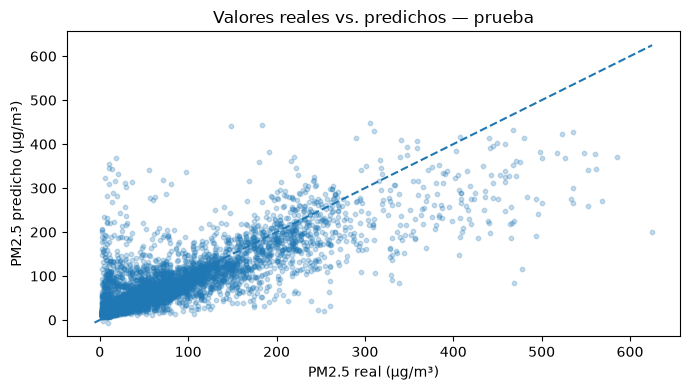

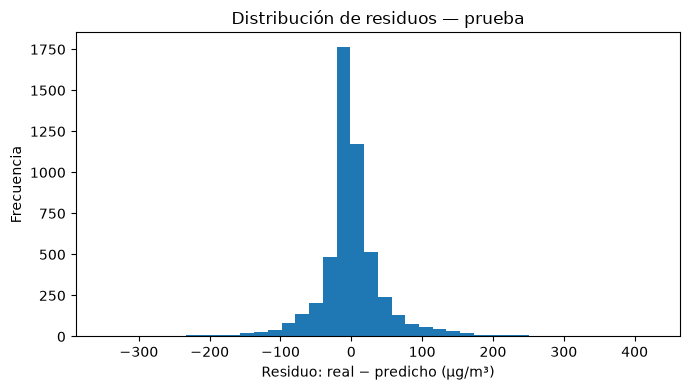

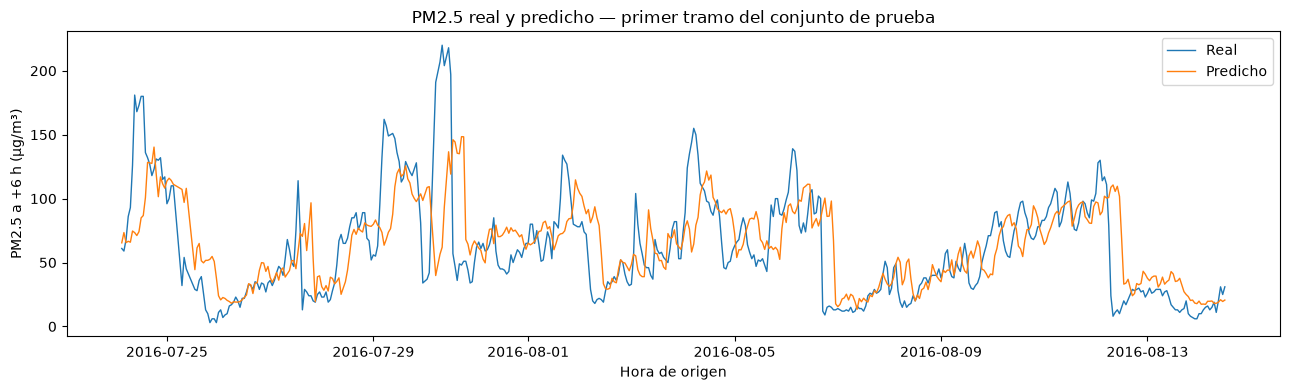

In [25]:
residuals = y_test.to_numpy() - test_predictions

plt.figure(figsize=(7, 4))
plt.scatter(y_test, test_predictions, alpha=0.25, s=10)
lims = [
    min(float(y_test.min()), float(test_predictions.min())),
    max(float(y_test.max()), float(test_predictions.max())),
]
plt.plot(lims, lims, linestyle="--")
plt.title("Valores reales vs. predichos — prueba")
plt.xlabel("PM2.5 real (µg/m³)")
plt.ylabel("PM2.5 predicho (µg/m³)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(residuals, bins=40)
plt.title("Distribución de residuos — prueba")
plt.xlabel("Residuo: real − predicho (µg/m³)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "Real": y_test,
    "Predicho": test_predictions,
}, index=X_test.index).sort_index().iloc[:500]

plt.figure(figsize=(13, 4))
plt.plot(comparison.index, comparison["Real"], label="Real", linewidth=1)
plt.plot(comparison.index, comparison["Predicho"], label="Predicho", linewidth=1)
plt.title("PM2.5 real y predicho — primer tramo del conjunto de prueba")
plt.xlabel("Hora de origen")
plt.ylabel("PM2.5 a +6 h (µg/m³)")
plt.legend()
plt.tight_layout()
plt.show()


In [26]:
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "wanliu_pm25_6h.joblib"
metadata_path = models_dir / "wanliu_pm25_6h_metadata.json"

joblib.dump(final_model, model_path)

metadata = {
    "station": "Wanliu",
    "model_name": selected_name,
    "model_version": "wanliu-pm25-6h-research",
    "target": "pm25",
    "target_definition": "PM2.5 exactamente 6 horas después de la hora de origen",
    "horizon_hours": HORIZON_HOURS,
    "feature_count": len(FEATURE_COLUMNS),
    "feature_columns": FEATURE_COLUMNS,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "best_params": selected_search.best_params_,
    "validation_metrics": selected_validation_metrics,
    "baseline_validation_metrics": baseline_validation_metrics,
    "test_metrics": final_test_metrics,
    "baseline_test_metrics": baseline_test_metrics,
    "beats_persistence_validation": bool(beats_baseline_validation),
    "training_examples": int(len(final_training)),
    "validation_examples": int(len(validation)),
    "test_examples": int(len(test)),
    "dataset_file": DATASET_NAME,
    "training_started_at_utc": datetime.now(timezone.utc).isoformat(),
    "notes": (
        "Pipeline experimental generado por el notebook 04. "
        "Integrar las mismas transformaciones en la API antes de usarlo en producción."
    ),
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Modelo guardado en:", model_path)
print("Metadatos guardados en:", metadata_path)


Modelo guardado en: c:\Users\PC\Proyectos\beijing-pm25-crisp-mlq\models\wanliu_pm25_6h.joblib
Metadatos guardados en: c:\Users\PC\Proyectos\beijing-pm25-crisp-mlq\models\wanliu_pm25_6h_metadata.json
